# Lesson 9 — Charts & exporting reports
**Goal:** turn analysis into something a manager can see and open: pandas charts saved as images, and a multi-sheet Excel report.

In [1]:
import pandas as pd, matplotlib.pyplot as plt
orders   = pd.read_csv('data/orders.csv', parse_dates=['order_date'])
products = pd.read_csv('data/products.csv')
orders = orders.merge(products[['product_id', 'category']], on='product_id')
orders['revenue'] = orders['quantity'] * orders['unit_price'] * (1 - orders['discount_pct']/100)

## Line chart: monthly revenue

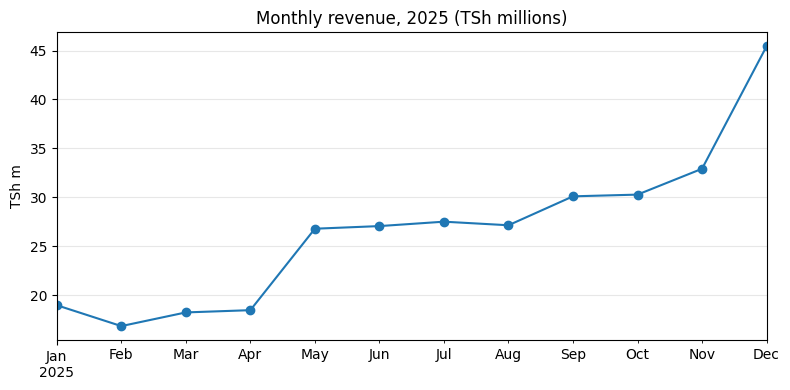

In [2]:
monthly = orders.set_index('order_date')['revenue'].resample('ME').sum() / 1e6
ax = monthly.plot(kind='line', marker='o', figsize=(8, 4), title='Monthly revenue, 2025 (TSh millions)')
ax.set_xlabel(''); ax.set_ylabel('TSh m'); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig('monthly_revenue.png', dpi=120); plt.show()

## Bar chart: revenue by category

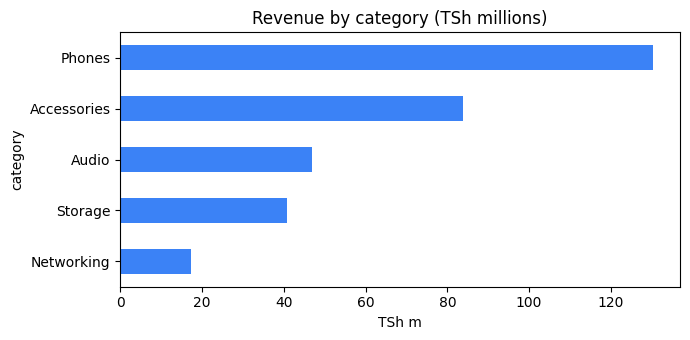

In [3]:
by_cat = orders.groupby('category')['revenue'].sum().sort_values() / 1e6
ax = by_cat.plot(kind='barh', figsize=(7, 3.5), title='Revenue by category (TSh millions)', color='#3b82f6')
ax.set_xlabel('TSh m'); plt.tight_layout(); plt.show()

## Stacked bars: channel mix per branch

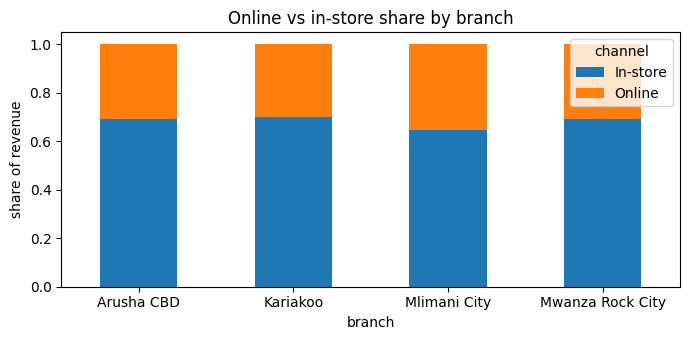

In [4]:
mix = pd.crosstab(orders['branch'], orders['channel'], values=orders['revenue'], aggfunc='sum', normalize='index')
ax = mix.plot(kind='bar', stacked=True, figsize=(7, 3.5), title='Online vs in-store share by branch', rot=0)
ax.set_ylabel('share of revenue'); plt.tight_layout(); plt.show()

## Export a multi-sheet Excel report

In [5]:
branch_summary = orders.groupby('branch').agg(orders=('order_id', 'count'), revenue=('revenue', 'sum')).round(0)
with pd.ExcelWriter('sales_report_2025.xlsx') as xl:
    branch_summary.to_excel(xl, sheet_name='By branch')
    (monthly * 1e6).round(0).to_frame('revenue').to_excel(xl, sheet_name='By month')
    orders.to_excel(xl, sheet_name='All orders', index=False)
pd.ExcelFile('sales_report_2025.xlsx').sheet_names

['By branch', 'By month', 'All orders']

In [6]:
branch_summary.to_csv('branch_summary.csv')   # CSV for other tools
print(open('branch_summary.csv').read())

branch,orders,revenue
Arusha CBD,458,64620500.0
Kariakoo,835,107063150.0
Mlimani City,720,98931100.0
Mwanza Rock City,387,49019550.0



## Key takeaways
- `Series.plot(kind='line'|'bar'|'barh'|...)`, then `plt.savefig()` to keep the image.
- `pd.ExcelWriter` writes several DataFrames to one workbook — a ready-made report.

**Exercise:** make a bar chart of the number of orders per payment method and save it as `payments.png`.